# Credit Card Fraud Detection - Model Evaluation

This notebook evaluates the three models from the model-selection step (KNN, Random Forest, SVM) on the **held-out test set**.

Model selection compared the models with cross-validation on the training data and picked a winner by F1 score at each model's default decision threshold. Here we go further:

1. Rebuild the same models on the same train/test split
2. Compare them on the untouched test set, with a "predict nothing" baseline for context
3. Compare ROC and Precision-Recall curves (threshold-independent)
4. Tune the decision threshold **using only training data**, then re-evaluate on the test set
5. Look at an "alert budget" view (what if analysts can only review the top N% riskiest transactions?)
6. Interpret the best model and analyse its errors

**Why not just accuracy?** Only about 2% of transactions are fraud, so a model that never flags anything is ~98% accurate. We focus on precision, recall, F1 and PR-AUC for the fraud class.

In [16]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score, matthews_corrcoef,
                             confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve,
                             roc_curve, classification_report)

## Step 1: Load data and recreate the model-selection setup

Same preprocessing, same split (`test_size=0.20`, `random_state=42`, stratified) and same model settings as `Model_Selection.ipynb`, so the results are comparable.

In [17]:
df = pd.read_csv("Data/credit_fraud_data.csv")

target_col = "is_fraud"
X = df.drop(columns=[target_col, "transaction_datetime"])   # raw timestamp removed, as in model selection
y = df[target_col]

numeric_features = X.select_dtypes(include=np.number).columns
categorical_features = X.select_dtypes(exclude=np.number).columns

def make_preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Fraud rate  train: %.3f%%   test: %.3f%%" % (100*y_train.mean(), 100*y_test.mean()))
print("Frauds in test set:", y_test.sum())

Train: (80000, 48) | Test: (20000, 48)
Fraud rate  train: 2.055%   test: 2.055%
Frauds in test set: 411


In [18]:
models = {
    "KNN": make_pipeline(make_preprocessor(), KNeighborsClassifier(n_neighbors=5, n_jobs=-1)),
    "Random Forest": make_pipeline(make_preprocessor(),
        RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1)),
    "SVM": make_pipeline(make_preprocessor(),
        LinearSVC(class_weight="balanced", random_state=42, max_iter=5000, dual="auto")),
}
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

for name, m in models.items():
    m.fit(X_train, y_train)
    print("Fitted:", name)

def get_scores(model, X_):
    """Continuous fraud score. LinearSVC has no predict_proba, so use decision_function."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_)[:, 1]
    return model.decision_function(X_)

test_scores = {name: get_scores(m, X_test) for name, m in models.items()}

Fitted: KNN
Fitted: Random Forest
Fitted: SVM


## Step 2: Test-set performance at the default threshold

This is what the model-selection notebook effectively used. The baseline row is a model that predicts "not fraud" for everything, which shows why accuracy is misleading.

In [19]:
def metrics_row(y_true, y_pred, scores=None):
    row = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "MCC": matthews_corrcoef(y_true, y_pred),
    }
    if scores is not None:
        row["ROC-AUC"] = roc_auc_score(y_true, scores)
        row["PR-AUC"] = average_precision_score(y_true, scores)
    return row

rows = {"Baseline (never fraud)": metrics_row(y_test, baseline.predict(X_test))}
for name, m in models.items():
    rows[name] = metrics_row(y_test, m.predict(X_test), test_scores[name])

default_results = pd.DataFrame(rows).T
default_results.round(3)

,Accuracy,Balanced Acc,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC
Baseline (never fraud),0.979,0.500,0.000,0.000,0.000,0.000,NaN,NaN
KNN,0.979,0.504,0.211,0.010,0.019,0.041,0.587,0.036
Random Forest,0.979,0.503,0.273,0.007,0.014,0.042,0.825,0.117
SVM,0.716,0.754,0.055,0.793,0.103,0.158,0.840,0.121


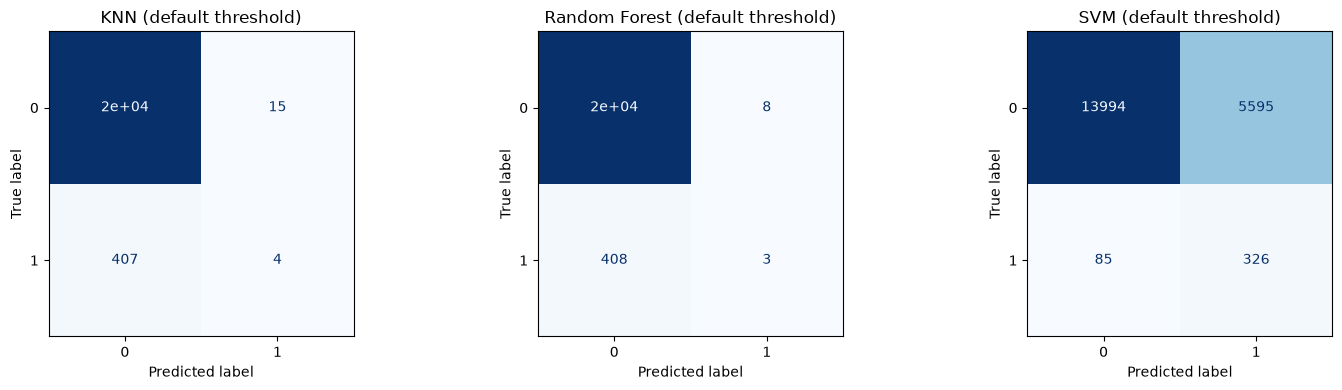

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, m) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name + " (default threshold)")
plt.tight_layout(); plt.show()

**Reading the matrices:** a *false negative* (bottom-left) is fraud that slipped through. A *false positive* (top-right) is a legitimate transaction wrongly flagged.

Note how differently the models behave at their default thresholds: KNN and Random Forest almost never predict fraud (high precision on very few flags, but they miss nearly all fraud), while the class-weighted SVM flags a lot of transactions (high recall, very low precision). The thresholds, not necessarily the models themselves, are driving much of this difference, which motivates Step 4.

## Step 3: Threshold-independent comparison (ROC and Precision-Recall curves)

These curves look at each model's ranking ability across all thresholds. With heavy class imbalance the Precision-Recall curve is the more informative of the two. The dotted line on the PR plot is the fraud rate, which is what a random model would achieve.

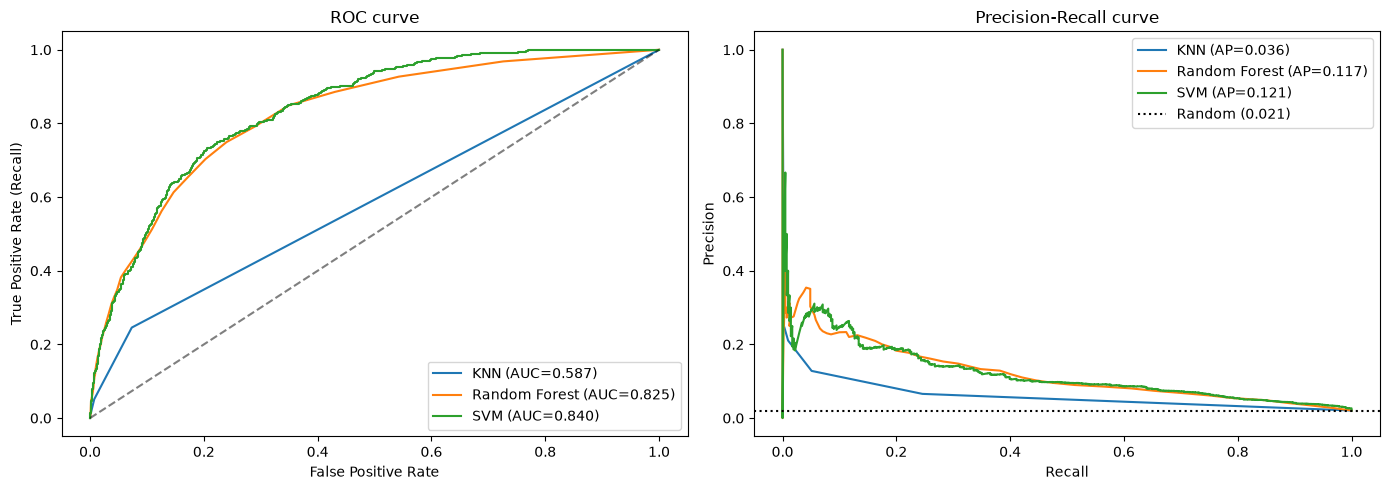

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, s in test_scores.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=.5)
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate (Recall)", title="ROC curve")
axes[0].legend()

for name, s in test_scores.items():
    p, r, _ = precision_recall_curve(y_test, s)
    axes[1].plot(r, p, label=f"{name} (AP={average_precision_score(y_test, s):.3f})")
axes[1].axhline(y_test.mean(), color="k", ls=":", label=f"Random ({y_test.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-Recall curve")
axes[1].legend()
plt.tight_layout(); plt.show()

## Step 4: Threshold tuning (without touching the test set)

Each model's default threshold is arbitrary. To pick a better one fairly:

1. Generate **out-of-fold** scores on the *training* data with 5-fold stratified CV
2. Choose the threshold that maximises F1 on those out-of-fold scores
3. Apply that fixed threshold to the test set

Choosing the threshold on the test set itself would leak information and inflate the results.

In [22]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
best_thresholds = {}

for name, m in models.items():
    method = "predict_proba" if hasattr(m, "predict_proba") else "decision_function"
    oof = cross_val_predict(m, X_train, y_train, cv=cv, method=method, n_jobs=1)
    if method == "predict_proba":
        oof = oof[:, 1]
    prec, rec, thr = precision_recall_curve(y_train, oof)
    f1 = 2 * prec * rec / (prec + rec + 1e-12)
    best_thresholds[name] = thr[np.argmax(f1[:-1])]
    print(f"{name:14s} chosen threshold = {best_thresholds[name]:.3f}   (out-of-fold F1 = {f1[:-1].max():.3f})")

KNN            chosen threshold = 0.200   (out-of-fold F1 = 0.108)
Random Forest  chosen threshold = 0.210   (out-of-fold F1 = 0.194)
SVM            chosen threshold = 0.729   (out-of-fold F1 = 0.208)


In [23]:
tuned_pred = {name: (test_scores[name] >= best_thresholds[name]).astype(int) for name in models}

tuned_results = pd.DataFrame({name: metrics_row(y_test, tuned_pred[name], test_scores[name])
                              for name in models}).T
tuned_results["Flagged"] = [int(tuned_pred[n].sum()) for n in models]
print("Test-set results at tuned thresholds")
display(tuned_results.round(3))

compare = pd.DataFrame({
    "F1 (default)": default_results.loc[list(models), "F1"],
    "F1 (tuned)": tuned_results["F1"],
    "Recall (default)": default_results.loc[list(models), "Recall"],
    "Recall (tuned)": tuned_results["Recall"],
    "Precision (default)": default_results.loc[list(models), "Precision"],
    "Precision (tuned)": tuned_results["Precision"],
})
compare.round(3)

Test-set results at tuned thresholds


,Accuracy,Balanced Acc,Precision,Recall,F1,MCC,ROC-AUC,PR-AUC,Flagged
KNN,0.913,0.586,0.066,0.246,0.104,0.092,0.587,0.036,1537
Random Forest,0.957,0.616,0.161,0.260,0.199,0.184,0.825,0.117,664
SVM,0.965,0.593,0.187,0.204,0.195,0.178,0.840,0.121,450


,F1 (default),F1 (tuned),Recall (default),Recall (tuned),Precision (default),Precision (tuned)
KNN,0.019,0.104,0.010,0.246,0.211,0.066
Random Forest,0.014,0.199,0.007,0.260,0.273,0.161
SVM,0.103,0.195,0.793,0.204,0.055,0.187


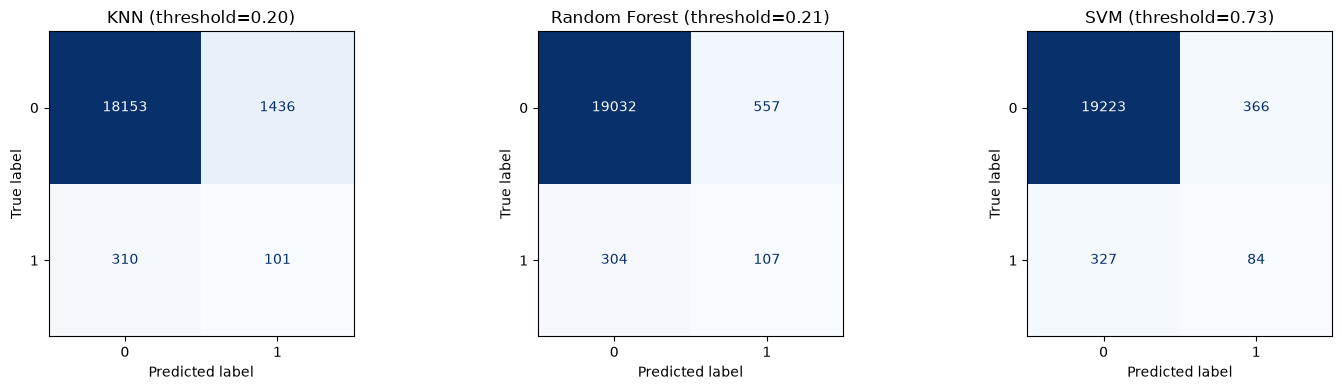

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, tuned_pred[name], ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} (threshold={best_thresholds[name]:.2f})")
plt.tight_layout(); plt.show()

## Step 5: Alert-budget view

In practice a fraud team can only review so many transactions. If we rank all test transactions by model score and review only the top 1%, 5% or 10%, how many frauds do we catch? This needs no threshold at all. **Lift** is how many times better than random review the model is.

In [25]:
rows = []
n_fraud = y_test.sum()
for name, s in test_scores.items():
    order = np.argsort(-s)
    for frac in (0.01, 0.05, 0.10, 0.20):
        k = int(len(s) * frac)
        caught = y_test.values[order[:k]].sum()
        rows.append({"Model": name, "Reviewed": f"top {int(frac*100)}%", "Transactions": k,
                     "Frauds caught": int(caught), "Recall": caught / n_fraud,
                     "Precision": caught / k, "Lift": (caught / k) / y_test.mean()})
budget = pd.DataFrame(rows)
budget.pivot(index="Reviewed", columns="Model", values="Recall").loc[["top 1%","top 5%","top 10%","top 20%"]].round(3)

Model,KNN,Random Forest,SVM
Reviewed,,,
top 1%,0.054,0.112,0.119
top 5%,0.151,0.336,0.326
top 10%,0.255,0.467,0.474
top 20%,0.324,0.684,0.706


In [26]:
budget.round(3)

,Model,Reviewed,Transactions,Frauds caught,Recall,Precision,Lift
0,KNN,top 1%,200,22,0.054,0.110,5.353
1,KNN,top 5%,1000,62,0.151,0.062,3.017
2,KNN,top 10%,2000,105,0.255,0.052,2.555
3,KNN,top 20%,4000,133,0.324,0.033,1.618
4,Random Forest,top 1%,200,46,0.112,0.230,11.192
5,Random Forest,top 5%,1000,138,0.336,0.138,6.715
6,Random Forest,top 10%,2000,192,0.467,0.096,4.672
7,Random Forest,top 20%,4000,281,0.684,0.070,3.418
8,SVM,top 1%,200,49,0.119,0.245,11.922
9,SVM,top 5%,1000,134,0.326,0.134,6.521


## Step 6: Interpreting the model

Permutation importance on the test set: how much does PR-AUC drop when one feature is shuffled? Run on Random Forest (the SVM is a linear model, so its coefficients are shown too).

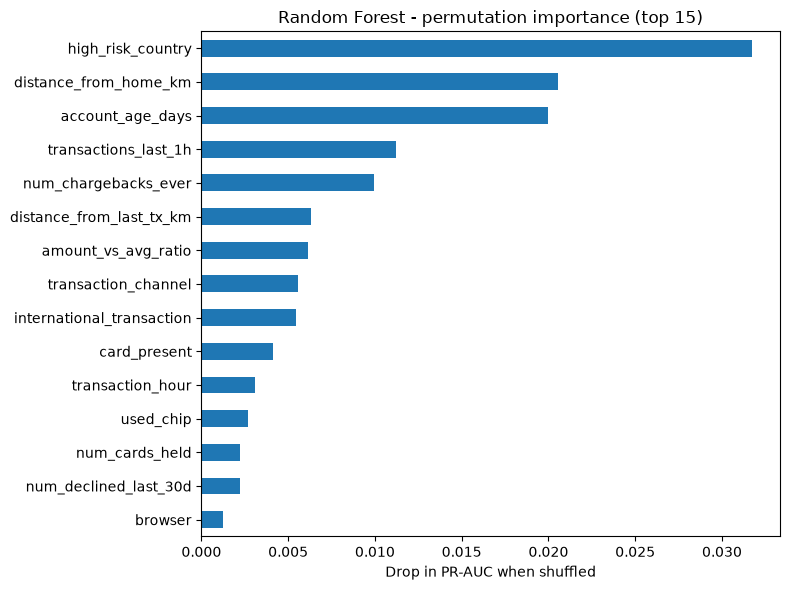

In [27]:
rf = models["Random Forest"]
perm = permutation_importance(rf, X_test, y_test, scoring="average_precision",
                              n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

imp.tail(15).plot(kind="barh", figsize=(8, 6))
plt.xlabel("Drop in PR-AUC when shuffled"); plt.title("Random Forest - permutation importance (top 15)")
plt.tight_layout(); plt.show()

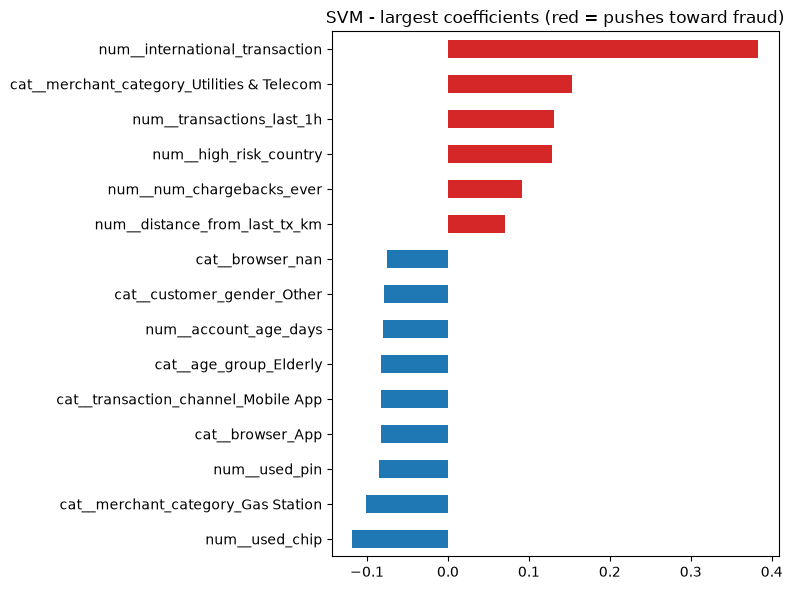

In [28]:
svm = models["SVM"]
feat_names = svm[0].get_feature_names_out()
coefs = pd.Series(svm[-1].coef_.ravel(), index=feat_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(15)
top.sort_values().plot(kind="barh", figsize=(8, 6), color=(top.sort_values() > 0).map({True: "tab:red", False: "tab:blue"}))
plt.title("SVM - largest coefficients (red = pushes toward fraud)")
plt.tight_layout(); plt.show()

## Step 7: Error analysis

Where does the best tuned model miss fraud? We use the tuned Random Forest and break test-set recall down by a few categories.

In [29]:
name = "Random Forest"
err = X_test.copy()
err["is_fraud"] = y_test.values
err["pred"] = tuned_pred[name]

def recall_by(col):
    g = err[err.is_fraud == 1].groupby(col).agg(frauds=("pred", "size"), caught=("pred", "sum"))
    g["recall"] = g.caught / g.frauds
    return g.sort_values("recall")

for col in ["transaction_channel", "merchant_category", "device_type"]:
    print(f"\nRecall by {col}"); display(recall_by(col).round(3))


Recall by transaction_channel


,frauds,caught,recall
transaction_channel,,,
In-store,57,1,0.018
ATM,12,1,0.083
Mobile App,45,7,0.156
Online,297,98,0.330



Recall by merchant_category


,frauds,caught,recall
merchant_category,,,
Education,4,0,0.000
Financial Services,2,0,0.000
Utilities & Telecom,4,0,0.000
Gas Station,38,4,0.105
Restaurant & Dining,45,8,0.178
Electronics & Technology,21,4,0.190
Grocery & Supermarket,42,9,0.214
Travel & Airlines,33,8,0.242
Entertainment & Streaming,32,8,0.250



Recall by device_type


,frauds,caught,recall
device_type,,,
POS Terminal,57,1,0.018
ATM,12,1,0.083
Mobile,218,63,0.289
Desktop,124,42,0.339


In [30]:
# What do the missed frauds look like compared with caught frauds?
fraud_rows = err[err.is_fraud == 1]
cols = ["distance_from_home_km", "account_age_days", "num_chargebacks_ever", "transactions_last_1h",
        "amount_vs_avg_ratio", "high_risk_country", "international_transaction", "card_present"]
fraud_rows.groupby("pred")[cols].mean().rename(index={0: "Missed (FN)", 1: "Caught (TP)"}).round(2)

,distance_from_home_km,account_age_days,num_chargebacks_ever,transactions_last_1h,amount_vs_avg_ratio,high_risk_country,international_transaction,card_present
pred,,,,,,,,
Missed (FN),6831.25,663.82,0.67,1.12,2.52,0.14,0.89,0.18
Caught (TP),7297.06,389.79,0.79,1.94,4.06,0.56,1.00,0.01


## Conclusions

**1. Default-threshold results are misleading.** At default thresholds, KNN and Random Forest catch under 1% of fraud (recall 0.010 and 0.007) while the class-weighted SVM catches 79% of it but with only 5.5% precision (F1 0.103). The F1-based selection in the previous notebook favoured the SVM largely because of this threshold behaviour, not because it ranks transactions much better.

**2. Once thresholds are tuned (on training data only), Random Forest and SVM are effectively tied.** Test F1 is 0.199 (RF) vs 0.195 (SVM); PR-AUC is 0.117 vs 0.121; ROC-AUC is 0.825 vs 0.840. With only 411 frauds in the test set, differences this small are within noise. KNN is clearly the weakest (PR-AUC 0.036, ROC-AUC 0.587), partly because distance in a one-hot, 48-feature space is not very informative and it has no class weighting.

**3. Absolute performance is modest.** At the tuned thresholds the best models catch roughly 20-26% of fraud with 16-19% precision. Reviewing the top 10% riskiest transactions catches about 47% of fraud (about 4.7x better than random review), and the top 20% catches 68-71%. That is a useful ranking signal but not a strong standalone detector.

**4. The models are much better at online fraud than in-person fraud.** For the tuned Random Forest, recall is about 33% for Online transactions but only about 2% for In-store/POS and 8% for ATM. Caught frauds are far more likely to involve a high-risk country, multiple transactions in the last hour, and an unusually large amount relative to the customer's average. Frauds that look "normal" on these features are mostly missed.

**5. Most important features** (permutation importance) include `high_risk_country`, `distance_from_home_km`, `account_age_days`, `num_chargebacks_ever` and `transactions_last_1h`.

**Recommendation.** Treat Random Forest and SVM as roughly equivalent; Random Forest offers feature importances and probability outputs, while the linear SVM is faster to train. Use a tuned threshold (or an alert-budget approach) rather than `predict()`. Possible next steps: tree-based boosting (e.g. gradient boosting), resampling or cost-sensitive learning, engineered features for in-store/ATM fraud, and a cost-based threshold using real fraud-loss vs. review-cost figures.